# Experiment 05: Regularization, Batch Normalization, Early Stopping & Confusion Matrix Analysis

**Course/Lab Topic:** Deep Learning  
**Framework:** PyTorch  
**Dataset:** MNIST handwritten digits  
**Platform:** Google Colab

### Experiment focus
This notebook demonstrates model fitting and common techniques used to reduce overfitting:

- Baseline model
- L1 regularization
- L2 regularization (weight decay)
- Dropout
- Batch Normalization
- Early Stopping
- Combined regularization
- Confusion Matrix analysis
- Precision, Recall and F1-score

> **Note:** The uploaded experiment material is centered on model fitting and regularization techniques, including early stopping, L1/L2, batch normalization and dropout. This notebook converts those topics into a reproducible PyTorch demonstration and adds quantitative evaluation.

## 1. Objectives

By completing this experiment, students should be able to:

1. Understand the difference between underfitting, good fitting and overfitting.
2. Build a neural network classifier for MNIST.
3. Observe overfitting using training and validation curves.
4. Apply L1 regularization.
5. Apply L2 regularization through the Adam optimizer's `weight_decay`.
6. Apply Dropout.
7. Apply Batch Normalization.
8. Implement Early Stopping based on validation loss.
9. Compare the performance of different regularization strategies.
10. Analyze classification performance using a confusion matrix, precision, recall and F1-score.

## 2. Theory

### 2.1 Model fitting

A model should learn useful patterns from the training data and generalize them to unseen data.

- **Underfitting:** training and validation performance are both poor.
- **Good fitting:** training and validation performance are both good and reasonably close.
- **Overfitting:** training performance becomes very high while validation performance stops improving or becomes worse.

A common visual indication of overfitting is a widening gap between training and validation accuracy, together with increasing validation loss.

### 2.2 Regularization

Regularization adds constraints or noise during training so that the model is less likely to memorize the training data.

### 2.3 L1 Regularization

L1 adds a penalty proportional to the absolute value of model parameters:

\[
L_{total}=L_{data}+\lambda\sum_i |w_i|
\]

L1 can encourage some parameters toward zero and can therefore produce sparse models.

### 2.4 L2 Regularization

L2 adds a squared-weight penalty:

\[
L_{total}=L_{data}+\lambda\sum_i w_i^2
\]

In PyTorch, L2-style weight decay can be applied conveniently through the optimizer's `weight_decay` parameter.

### 2.5 Dropout

Dropout randomly deactivates a fraction of neurons during training. This reduces reliance on particular neurons and can improve generalization.

### 2.6 Batch Normalization

Batch Normalization normalizes intermediate activations during training. It can stabilize and speed up optimization and may also provide a regularizing effect.

### 2.7 Early Stopping

Early stopping monitors validation performance and stops training when validation loss has not improved for a specified number of epochs (`patience`).

### 2.8 Confusion Matrix

For a multi-class classifier, the confusion matrix shows how often each true class is predicted as each class. For MNIST, rows represent true digits and columns represent predicted digits.

## 3. Experimental Design

To make the effect of regularization easier to observe, this experiment intentionally uses a **small training subset** of MNIST and a relatively high-capacity multilayer perceptron.

The following models are compared:

| Model | Main technique |
|---|---|
| Baseline | No explicit regularization |
| L1 | L1 parameter penalty |
| L2 | Adam weight decay |
| Dropout | Random neuron deactivation |
| BatchNorm | Batch normalization |
| Early Stopping | Validation-based stopping |
| Combined | BatchNorm + Dropout + L2 + Early Stopping |

**Important:** Exact numerical results will vary slightly between runs because of random initialization and data shuffling.

In [12]:
# ============================================================
# CELL 1: Install/Import Libraries
# ============================================================

import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader, Subset, random_split

import torchvision
import torchvision.transforms as transforms

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

print("PyTorch version:", torch.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

PyTorch version: 2.11.0+cpu
Device: cpu


In [13]:
# ============================================================
# CELL 2: Reproducibility
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Random seed:", SEED)

Random seed: 42


## 4. Load and Prepare the MNIST Dataset

MNIST contains grayscale images of handwritten digits from 0 to 9. Each image has a resolution of 28×28 pixels.

For this experiment, only a small subset is used deliberately. This makes the learning problem more prone to overfitting and makes the regularization techniques easier to compare.

In [14]:
# ============================================================
# CELL 3: Load MNIST
# ============================================================

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_full = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Full training samples:", len(train_full))
print("Test samples:", len(test_dataset))

Full training samples: 60000
Test samples: 10000


In [15]:
# ============================================================
# CELL 4: Create Small Training/Validation Set
# ============================================================

NUM_SAMPLES = 1000

g = torch.Generator().manual_seed(SEED)
selected_indices = torch.randperm(
    len(train_full),
    generator=g
)[:NUM_SAMPLES]

small_dataset = Subset(train_full, selected_indices)

train_size = int(0.80 * len(small_dataset))
val_size = len(small_dataset) - train_size

train_dataset, val_dataset = random_split(
    small_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(SEED)
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

Training samples: 800
Validation samples: 200
Test samples: 10000


In [16]:
# ============================================================
# CELL 5: DataLoaders
# ============================================================

BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Batch size:", BATCH_SIZE)

Batch size: 64


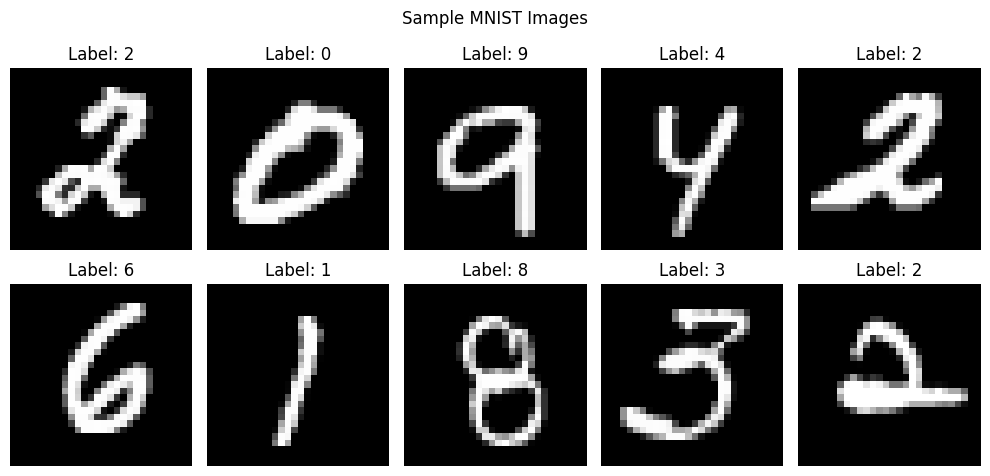

In [17]:
# ============================================================
# CELL 6: Visualize MNIST Samples
# ============================================================

images, labels = next(iter(train_loader))

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    img = images[i].squeeze().numpy()
    img = img * 0.3081 + 0.1307

    plt.imshow(img, cmap="gray")
    plt.title(f"Label: {labels[i].item()}")
    plt.axis("off")

plt.suptitle("Sample MNIST Images")
plt.tight_layout()
plt.show()

## 5. Build the Baseline Model

The baseline is intentionally high-capacity relative to the small training set. It contains several fully connected layers and uses ReLU activations.

No explicit L1/L2 penalty, Dropout, Batch Normalization or Early Stopping is used in this baseline.

In [18]:
# ============================================================
# CELL 7: Baseline MLP
# ============================================================

class BaselineMLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),

            nn.Linear(28 * 28, 1024),
            nn.ReLU(),

            nn.Linear(1024, 512),
            nn.ReLU(),

            nn.Linear(512, 256),
            nn.ReLU(),

            nn.Linear(256, 128),
            nn.ReLU(),

            nn.Linear(128, 64),
            nn.ReLU(),

            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.network(x)


model = BaselineMLP().to(device)
print(model)

BaselineMLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=1024, bias=True)
    (2): ReLU()
    (3): Linear(in_features=1024, out_features=512, bias=True)
    (4): ReLU()
    (5): Linear(in_features=512, out_features=256, bias=True)
    (6): ReLU()
    (7): Linear(in_features=256, out_features=128, bias=True)
    (8): ReLU()
    (9): Linear(in_features=128, out_features=64, bias=True)
    (10): ReLU()
    (11): Linear(in_features=64, out_features=10, bias=True)
  )
)


## 6. Training and Evaluation Functions

The following reusable functions:

- train a model,
- calculate training and validation loss,
- calculate training and validation accuracy,
- optionally apply L1 regularization,
- optionally apply early stopping,
- restore the best validation checkpoint.

In [19]:
# ============================================================
# CELL 8: Training Function
# ============================================================

def train_model(
    model,
    train_loader,
    val_loader,
    epochs=50,
    learning_rate=1e-3,
    weight_decay=0.0,
    l1_lambda=0.0,
    early_stopping=False,
    patience=5,
    verbose=True
):
    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    best_val_loss = float("inf")
    best_state = None
    patience_counter = 0

    for epoch in range(epochs):

        # -------------------------
        # Training
        # -------------------------
        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            data_loss = criterion(outputs, labels)

            # L1 penalty
            l1_penalty = torch.tensor(
                0.0,
                device=device
            )

            if l1_lambda > 0:
                for param in model.parameters():
                    l1_penalty += torch.sum(torch.abs(param))

            loss = data_loss + l1_lambda * l1_penalty

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            total += labels.size(0)
            correct += (predictions == labels).sum().item()

        train_loss = running_loss / total
        train_acc = correct / total

        # -------------------------
        # Validation
        # -------------------------
        model.eval()

        val_running_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                val_loss_batch = criterion(outputs, labels)

                val_running_loss += (
                    val_loss_batch.item() * images.size(0)
                )

                predictions = outputs.argmax(dim=1)

                val_total += labels.size(0)
                val_correct += (
                    (predictions == labels).sum().item()
                )

        val_loss = val_running_loss / val_total
        val_acc = val_correct / val_total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if verbose:
            print(
                f"Epoch {epoch+1:02d}/{epochs} | "
                f"Train Loss: {train_loss:.4f} | "
                f"Train Acc: {train_acc*100:.2f}% | "
                f"Val Loss: {val_loss:.4f} | "
                f"Val Acc: {val_acc*100:.2f}%"
            )

        # -------------------------
        # Early stopping
        # -------------------------
        if early_stopping:
            if val_loss < best_val_loss - 1e-5:
                best_val_loss = val_loss
                best_state = copy.deepcopy(model.state_dict())
                patience_counter = 0
            else:
                patience_counter += 1

                if patience_counter >= patience:
                    if verbose:
                        print(
                            f"Early stopping triggered at "
                            f"epoch {epoch+1}."
                        )
                    break

    # Restore best validation checkpoint
    if early_stopping and best_state is not None:
        model.load_state_dict(best_state)

    return history

In [20]:
# ============================================================
# CELL 9: Evaluation Function
# ============================================================

def evaluate_model(model, loader):
    model.eval()

    all_labels = []
    all_predictions = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1).cpu().numpy()

            all_predictions.extend(predictions)
            all_labels.extend(labels.numpy())

    y_true = np.array(all_labels)
    y_pred = np.array(all_predictions)

    accuracy = accuracy_score(y_true, y_pred)

    return accuracy, y_true, y_pred

In [21]:
# ============================================================
# CELL 10: Plot Training History
# ============================================================

def plot_history(history, title):
    epochs = range(1, len(history["train_loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

    # Accuracy
    axes[0].plot(
        epochs,
        history["train_acc"],
        label="Training Accuracy"
    )
    axes[0].plot(
        epochs,
        history["val_acc"],
        label="Validation Accuracy"
    )
    axes[0].set_title(f"{title}: Accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Loss
    axes[1].plot(
        epochs,
        history["train_loss"],
        label="Training Loss"
    )
    axes[1].plot(
        epochs,
        history["val_loss"],
        label="Validation Loss"
    )
    axes[1].set_title(f"{title}: Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

# Part A — Baseline Model

The baseline is trained for a fixed number of epochs without explicit regularization. Observe whether training accuracy continues to improve while validation performance stops improving.

Epoch 01/50 | Train Loss: 2.0424 | Train Acc: 26.50% | Val Loss: 1.5408 | Val Acc: 57.00%
Epoch 02/50 | Train Loss: 1.2492 | Train Acc: 56.12% | Val Loss: 1.0075 | Val Acc: 63.00%
Epoch 03/50 | Train Loss: 0.8300 | Train Acc: 68.88% | Val Loss: 0.7967 | Val Acc: 66.50%
Epoch 04/50 | Train Loss: 0.5447 | Train Acc: 80.25% | Val Loss: 0.5861 | Val Acc: 80.00%
Epoch 05/50 | Train Loss: 0.3445 | Train Acc: 87.50% | Val Loss: 0.5699 | Val Acc: 82.00%
Epoch 06/50 | Train Loss: 0.2297 | Train Acc: 92.25% | Val Loss: 0.4630 | Val Acc: 86.00%
Epoch 07/50 | Train Loss: 0.1322 | Train Acc: 96.50% | Val Loss: 0.6243 | Val Acc: 85.00%
Epoch 08/50 | Train Loss: 0.0893 | Train Acc: 97.75% | Val Loss: 0.5967 | Val Acc: 84.50%
Epoch 09/50 | Train Loss: 0.0740 | Train Acc: 97.75% | Val Loss: 0.6296 | Val Acc: 85.50%
Epoch 10/50 | Train Loss: 0.0594 | Train Acc: 97.50% | Val Loss: 0.5206 | Val Acc: 85.50%
Epoch 11/50 | Train Loss: 0.0356 | Train Acc: 98.88% | Val Loss: 0.7043 | Val Acc: 86.00%
Epoch 12/5

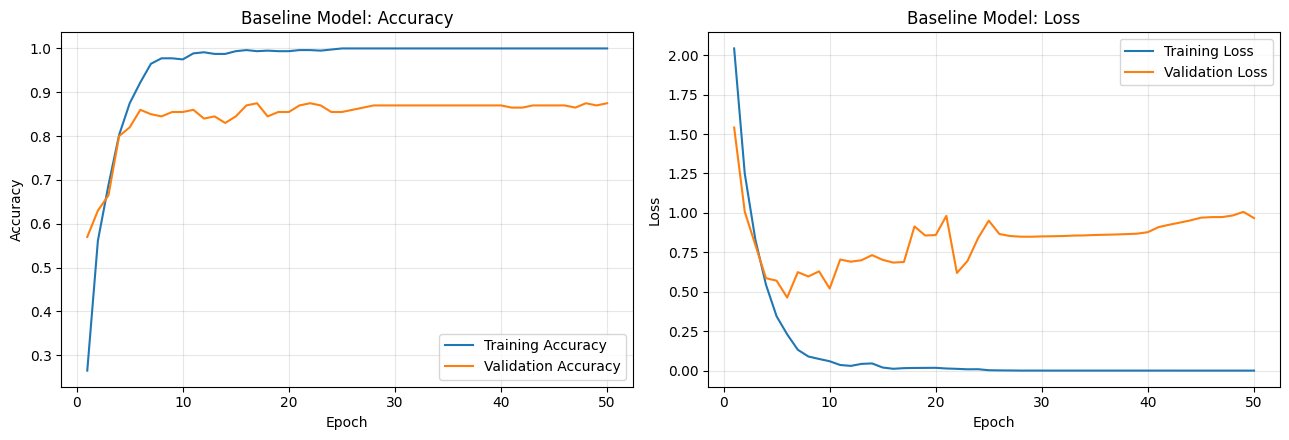

In [11]:
# ============================================================
# CELL 11: Train Baseline
# ============================================================

baseline_model = BaselineMLP().to(device)

baseline_history = train_model(
    baseline_model,
    train_loader,
    val_loader,
    epochs=50,
    learning_rate=1e-3,
    verbose=True
)

plot_history(
    baseline_history,
    "Baseline Model"
)

# Part B — L1 Regularization

L1 regularization adds an absolute-value penalty to model parameters.

A relatively small coefficient is used because the network contains many parameters and an excessively large L1 coefficient can dominate the classification loss.

Epoch 01/50 | Train Loss: 2.0687 | Train Acc: 27.38% | Val Loss: 1.5620 | Val Acc: 56.00%
Epoch 02/50 | Train Loss: 1.2642 | Train Acc: 56.50% | Val Loss: 0.9782 | Val Acc: 64.00%
Epoch 03/50 | Train Loss: 0.8500 | Train Acc: 71.88% | Val Loss: 0.8032 | Val Acc: 68.00%
Epoch 04/50 | Train Loss: 0.5450 | Train Acc: 80.88% | Val Loss: 0.5718 | Val Acc: 82.50%
Epoch 05/50 | Train Loss: 0.3684 | Train Acc: 87.75% | Val Loss: 0.5811 | Val Acc: 79.50%
Epoch 06/50 | Train Loss: 0.2695 | Train Acc: 91.88% | Val Loss: 0.4857 | Val Acc: 86.50%
Epoch 07/50 | Train Loss: 0.1685 | Train Acc: 96.25% | Val Loss: 0.5670 | Val Acc: 85.50%
Epoch 08/50 | Train Loss: 0.1215 | Train Acc: 97.50% | Val Loss: 0.5980 | Val Acc: 83.50%
Epoch 09/50 | Train Loss: 0.1020 | Train Acc: 97.75% | Val Loss: 0.6219 | Val Acc: 84.50%
Epoch 10/50 | Train Loss: 0.0839 | Train Acc: 98.12% | Val Loss: 0.5691 | Val Acc: 85.50%
Epoch 11/50 | Train Loss: 0.0563 | Train Acc: 99.38% | Val Loss: 0.6548 | Val Acc: 85.00%
Epoch 12/5

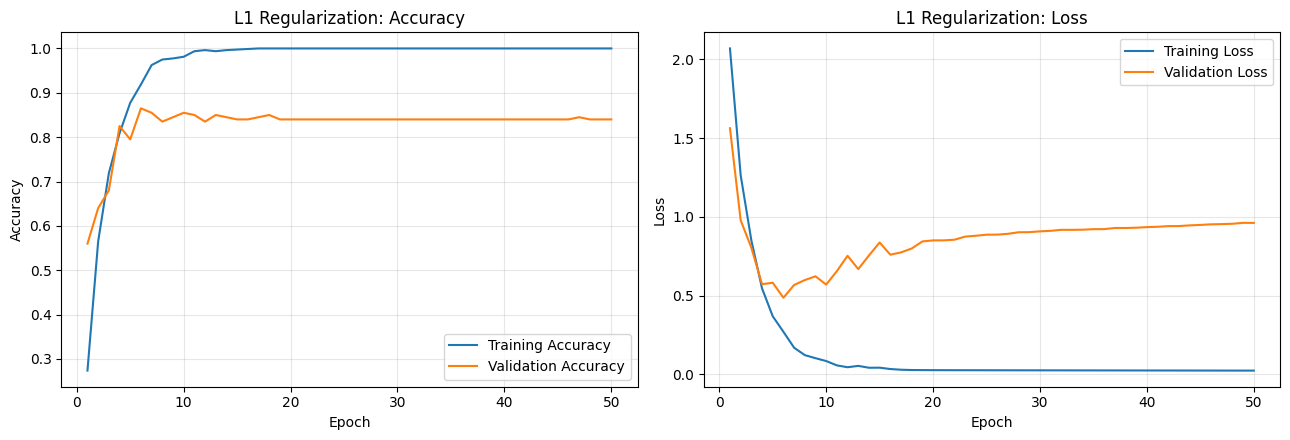

In [22]:
# ============================================================
# CELL 12: L1 Regularization
# ============================================================

l1_model = BaselineMLP().to(device)

L1_LAMBDA = 1e-6

l1_history = train_model(
    l1_model,
    train_loader,
    val_loader,
    epochs=50,
    learning_rate=1e-3,
    l1_lambda=L1_LAMBDA,
    verbose=True
)

plot_history(
    l1_history,
    "L1 Regularization"
)

# Part C — L2 Regularization

L2 regularization is implemented using Adam's `weight_decay` parameter. This penalizes large weights and is a standard practical approach to L2-style regularization.

Epoch 01/50 | Train Loss: 2.0868 | Train Acc: 29.88% | Val Loss: 1.5581 | Val Acc: 51.50%
Epoch 02/50 | Train Loss: 1.1539 | Train Acc: 60.75% | Val Loss: 1.0136 | Val Acc: 61.50%
Epoch 03/50 | Train Loss: 0.7958 | Train Acc: 72.75% | Val Loss: 0.7660 | Val Acc: 74.50%
Epoch 04/50 | Train Loss: 0.5517 | Train Acc: 81.12% | Val Loss: 0.8270 | Val Acc: 73.50%
Epoch 05/50 | Train Loss: 0.4094 | Train Acc: 86.75% | Val Loss: 0.5575 | Val Acc: 81.50%
Epoch 06/50 | Train Loss: 0.2300 | Train Acc: 93.38% | Val Loss: 0.5221 | Val Acc: 83.50%
Epoch 07/50 | Train Loss: 0.1448 | Train Acc: 96.00% | Val Loss: 0.6568 | Val Acc: 82.00%
Epoch 08/50 | Train Loss: 0.1108 | Train Acc: 96.12% | Val Loss: 0.5190 | Val Acc: 86.00%
Epoch 09/50 | Train Loss: 0.0773 | Train Acc: 98.12% | Val Loss: 0.6091 | Val Acc: 83.50%
Epoch 10/50 | Train Loss: 0.0408 | Train Acc: 99.00% | Val Loss: 0.6032 | Val Acc: 83.00%
Epoch 11/50 | Train Loss: 0.0280 | Train Acc: 99.12% | Val Loss: 0.6219 | Val Acc: 85.00%
Epoch 12/5

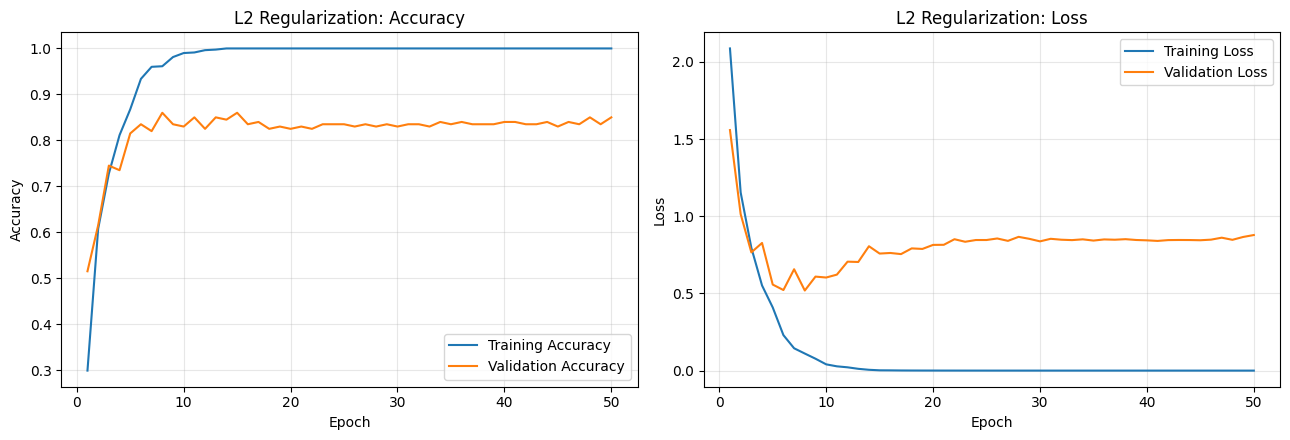

In [23]:
# ============================================================
# CELL 13: L2 Regularization
# ============================================================

l2_model = BaselineMLP().to(device)

L2_WEIGHT_DECAY = 1e-4

l2_history = train_model(
    l2_model,
    train_loader,
    val_loader,
    epochs=50,
    learning_rate=1e-3,
    weight_decay=L2_WEIGHT_DECAY,
    verbose=True
)

plot_history(
    l2_history,
    "L2 Regularization"
)

# Part D — Dropout

Dropout randomly sets a proportion of activations to zero during training. Here, different dropout probabilities are used at different depths of the network.

Epoch 01/50 | Train Loss: 2.2713 | Train Acc: 15.12% | Val Loss: 2.0855 | Val Acc: 29.00%
Epoch 02/50 | Train Loss: 1.9189 | Train Acc: 29.50% | Val Loss: 1.5372 | Val Acc: 49.50%
Epoch 03/50 | Train Loss: 1.4663 | Train Acc: 46.75% | Val Loss: 1.0672 | Val Acc: 58.50%
Epoch 04/50 | Train Loss: 1.1085 | Train Acc: 56.25% | Val Loss: 0.8459 | Val Acc: 68.50%
Epoch 05/50 | Train Loss: 0.8387 | Train Acc: 69.38% | Val Loss: 0.7408 | Val Acc: 74.50%
Epoch 06/50 | Train Loss: 0.6823 | Train Acc: 75.25% | Val Loss: 0.6746 | Val Acc: 78.50%
Epoch 07/50 | Train Loss: 0.5444 | Train Acc: 81.38% | Val Loss: 0.5271 | Val Acc: 82.50%
Epoch 08/50 | Train Loss: 0.4798 | Train Acc: 83.00% | Val Loss: 0.6219 | Val Acc: 83.00%
Epoch 09/50 | Train Loss: 0.4048 | Train Acc: 87.12% | Val Loss: 0.7116 | Val Acc: 84.00%
Epoch 10/50 | Train Loss: 0.4138 | Train Acc: 86.50% | Val Loss: 0.6096 | Val Acc: 85.50%
Epoch 11/50 | Train Loss: 0.3416 | Train Acc: 88.75% | Val Loss: 0.5570 | Val Acc: 86.00%
Epoch 12/5

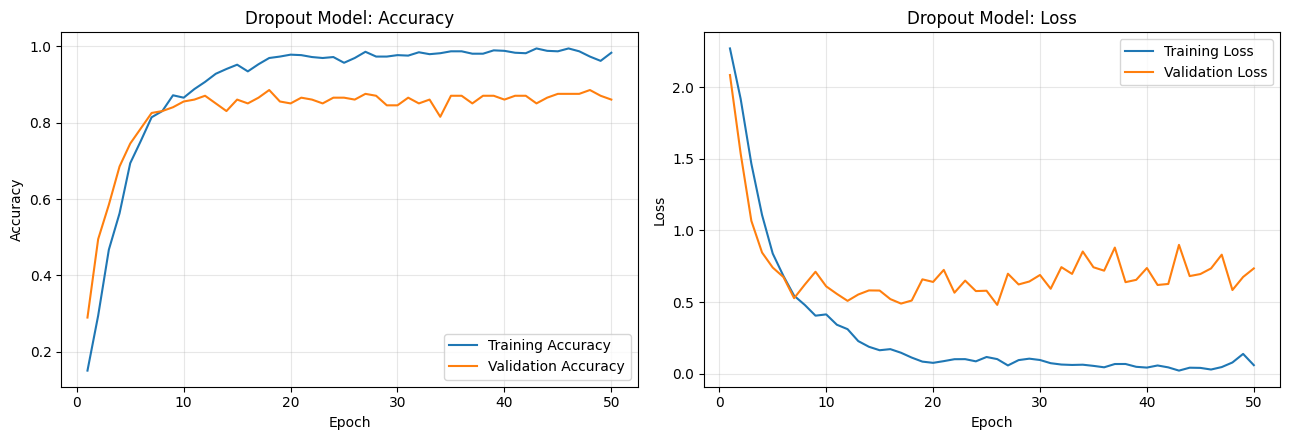

In [24]:
# ============================================================
# CELL 14: Dropout Model
# ============================================================

class DropoutMLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),

            nn.Linear(28 * 28, 1024),
            nn.ReLU(),
            nn.Dropout(0.50),

            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Dropout(0.50),

            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.40),

            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.30),

            nn.Linear(128, 64),
            nn.ReLU(),

            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.network(x)


dropout_model = DropoutMLP().to(device)

dropout_history = train_model(
    dropout_model,
    train_loader,
    val_loader,
    epochs=50,
    learning_rate=1e-3,
    verbose=True
)

plot_history(
    dropout_history,
    "Dropout Model"
)

# Part E — Batch Normalization

Batch Normalization is inserted after linear layers and before ReLU activations.

Epoch 01/50 | Train Loss: 1.5159 | Train Acc: 63.50% | Val Loss: 1.7319 | Val Acc: 80.50%
Epoch 02/50 | Train Loss: 0.8331 | Train Acc: 90.38% | Val Loss: 0.9214 | Val Acc: 84.50%
Epoch 03/50 | Train Loss: 0.5258 | Train Acc: 95.62% | Val Loss: 0.7112 | Val Acc: 87.50%
Epoch 04/50 | Train Loss: 0.3396 | Train Acc: 98.62% | Val Loss: 0.5891 | Val Acc: 89.00%
Epoch 05/50 | Train Loss: 0.2147 | Train Acc: 99.62% | Val Loss: 0.4713 | Val Acc: 90.50%
Epoch 06/50 | Train Loss: 0.1431 | Train Acc: 99.88% | Val Loss: 0.4375 | Val Acc: 90.00%
Epoch 07/50 | Train Loss: 0.1074 | Train Acc: 100.00% | Val Loss: 0.3932 | Val Acc: 90.00%
Epoch 08/50 | Train Loss: 0.0852 | Train Acc: 100.00% | Val Loss: 0.3967 | Val Acc: 90.00%
Epoch 09/50 | Train Loss: 0.0854 | Train Acc: 99.62% | Val Loss: 0.4183 | Val Acc: 89.00%
Epoch 10/50 | Train Loss: 0.0833 | Train Acc: 99.50% | Val Loss: 0.4747 | Val Acc: 85.00%
Epoch 11/50 | Train Loss: 0.1084 | Train Acc: 98.00% | Val Loss: 0.5279 | Val Acc: 84.00%
Epoch 12

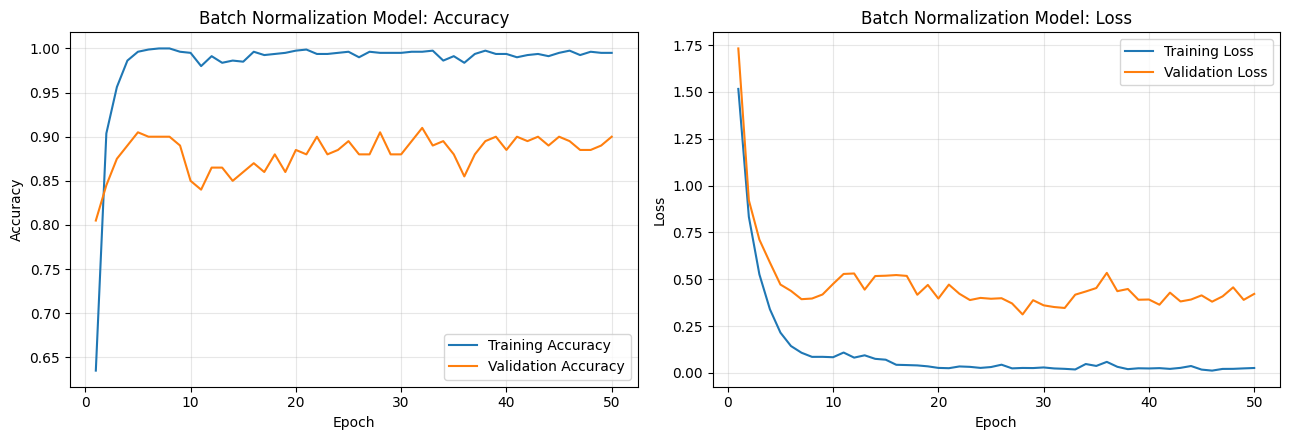

In [25]:
# ============================================================
# CELL 15: Batch Normalization Model
# ============================================================

class BatchNormMLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),

            nn.Linear(28 * 28, 1024),
            nn.BatchNorm1d(1024),
            nn.ReLU(),

            nn.Linear(1024, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),

            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),

            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.network(x)


batchnorm_model = BatchNormMLP().to(device)

batchnorm_history = train_model(
    batchnorm_model,
    train_loader,
    val_loader,
    epochs=50,
    learning_rate=1e-3,
    verbose=True
)

plot_history(
    batchnorm_history,
    "Batch Normalization Model"
)

# Part F — Early Stopping

The model is allowed to train for a maximum number of epochs, but training is stopped when validation loss fails to improve for a defined patience period.

Epoch 01/50 | Train Loss: 2.1081 | Train Acc: 25.25% | Val Loss: 1.5336 | Val Acc: 47.00%
Epoch 02/50 | Train Loss: 1.1514 | Train Acc: 61.38% | Val Loss: 0.7877 | Val Acc: 71.00%
Epoch 03/50 | Train Loss: 0.6872 | Train Acc: 75.25% | Val Loss: 0.6154 | Val Acc: 80.00%
Epoch 04/50 | Train Loss: 0.4870 | Train Acc: 84.62% | Val Loss: 0.4979 | Val Acc: 83.50%
Epoch 05/50 | Train Loss: 0.2824 | Train Acc: 91.38% | Val Loss: 0.5187 | Val Acc: 83.50%
Epoch 06/50 | Train Loss: 0.1806 | Train Acc: 94.12% | Val Loss: 0.4897 | Val Acc: 84.50%
Epoch 07/50 | Train Loss: 0.1499 | Train Acc: 95.38% | Val Loss: 0.4649 | Val Acc: 88.00%
Epoch 08/50 | Train Loss: 0.0904 | Train Acc: 97.25% | Val Loss: 0.5393 | Val Acc: 88.00%
Epoch 09/50 | Train Loss: 0.0584 | Train Acc: 98.50% | Val Loss: 0.4676 | Val Acc: 87.00%
Epoch 10/50 | Train Loss: 0.0585 | Train Acc: 97.88% | Val Loss: 0.5239 | Val Acc: 86.00%
Epoch 11/50 | Train Loss: 0.0546 | Train Acc: 98.12% | Val Loss: 0.6602 | Val Acc: 84.50%
Epoch 12/5

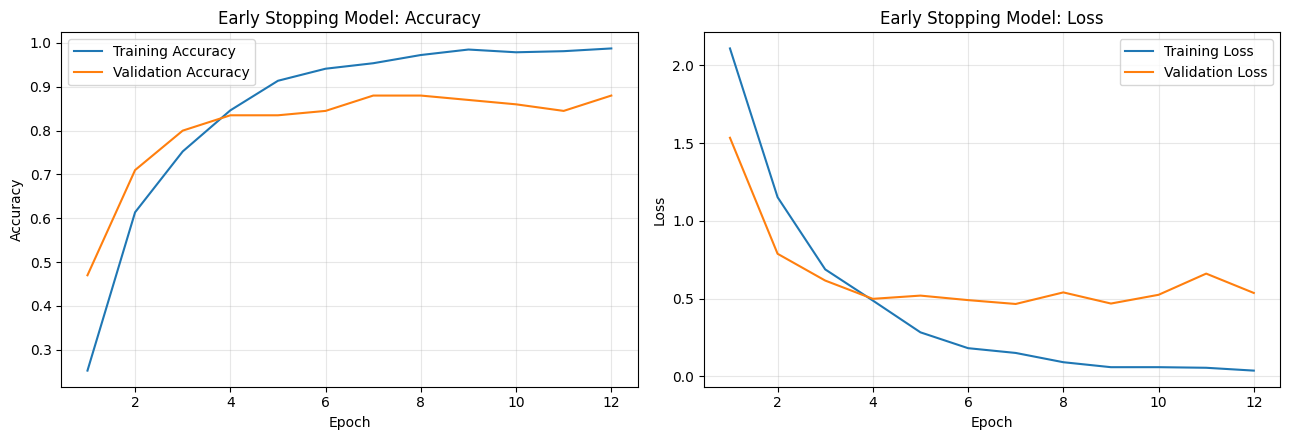

In [26]:
# ============================================================
# CELL 16: Early Stopping
# ============================================================

early_stop_model = BaselineMLP().to(device)

early_stop_history = train_model(
    early_stop_model,
    train_loader,
    val_loader,
    epochs=50,
    learning_rate=1e-3,
    early_stopping=True,
    patience=5,
    verbose=True
)

plot_history(
    early_stop_history,
    "Early Stopping Model"
)

# Part G — Combined Regularization

This model combines several techniques:

- Batch Normalization
- Dropout
- L2 regularization
- Early Stopping

The purpose is not to claim that combining every technique is always optimal, but to demonstrate how multiple regularization/stabilization strategies can be used together.

Epoch 01/50 | Train Loss: 2.1971 | Train Acc: 25.00% | Val Loss: 2.0800 | Val Acc: 45.00%
Epoch 02/50 | Train Loss: 1.7898 | Train Acc: 54.00% | Val Loss: 1.3791 | Val Acc: 66.00%
Epoch 03/50 | Train Loss: 1.3259 | Train Acc: 62.88% | Val Loss: 1.0074 | Val Acc: 71.00%
Epoch 04/50 | Train Loss: 0.9252 | Train Acc: 73.62% | Val Loss: 0.7448 | Val Acc: 75.00%
Epoch 05/50 | Train Loss: 0.6414 | Train Acc: 83.50% | Val Loss: 0.5686 | Val Acc: 85.00%
Epoch 06/50 | Train Loss: 0.4830 | Train Acc: 88.12% | Val Loss: 0.4987 | Val Acc: 86.00%
Epoch 07/50 | Train Loss: 0.3227 | Train Acc: 90.88% | Val Loss: 0.4227 | Val Acc: 87.00%
Epoch 08/50 | Train Loss: 0.2396 | Train Acc: 93.75% | Val Loss: 0.4779 | Val Acc: 87.00%
Epoch 09/50 | Train Loss: 0.2179 | Train Acc: 94.12% | Val Loss: 0.4298 | Val Acc: 86.00%
Epoch 10/50 | Train Loss: 0.2011 | Train Acc: 94.12% | Val Loss: 0.5594 | Val Acc: 83.50%
Epoch 11/50 | Train Loss: 0.1585 | Train Acc: 96.38% | Val Loss: 0.4900 | Val Acc: 88.00%
Epoch 12/5

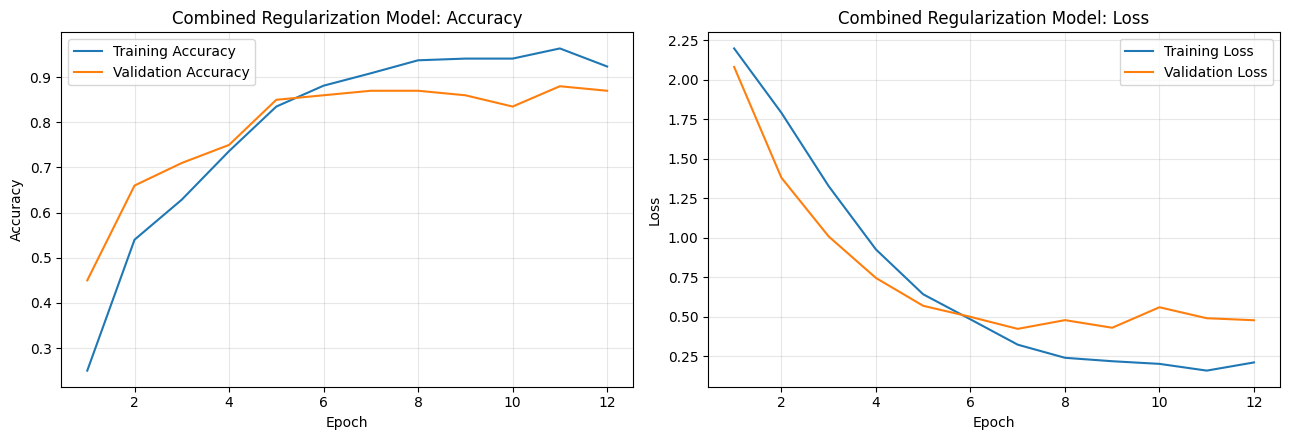

In [27]:
# ============================================================
# CELL 17: Combined Model
# ============================================================

class CombinedMLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),

            nn.Linear(28 * 28, 1024),
            nn.BatchNorm1d(1024),
            nn.ReLU(),
            nn.Dropout(0.50),

            nn.Linear(1024, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.50),

            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.40),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.30),

            nn.Linear(128, 64),
            nn.ReLU(),

            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.network(x)


combined_model = CombinedMLP().to(device)

combined_history = train_model(
    combined_model,
    train_loader,
    val_loader,
    epochs=50,
    learning_rate=1e-3,
    weight_decay=1e-4,
    early_stopping=True,
    patience=5,
    verbose=True
)

plot_history(
    combined_history,
    "Combined Regularization Model"
)

# 7. Compare Validation Curves

The next graph compares the validation accuracy and validation loss of all models. This is useful for discussing which method generalizes best on the validation set.

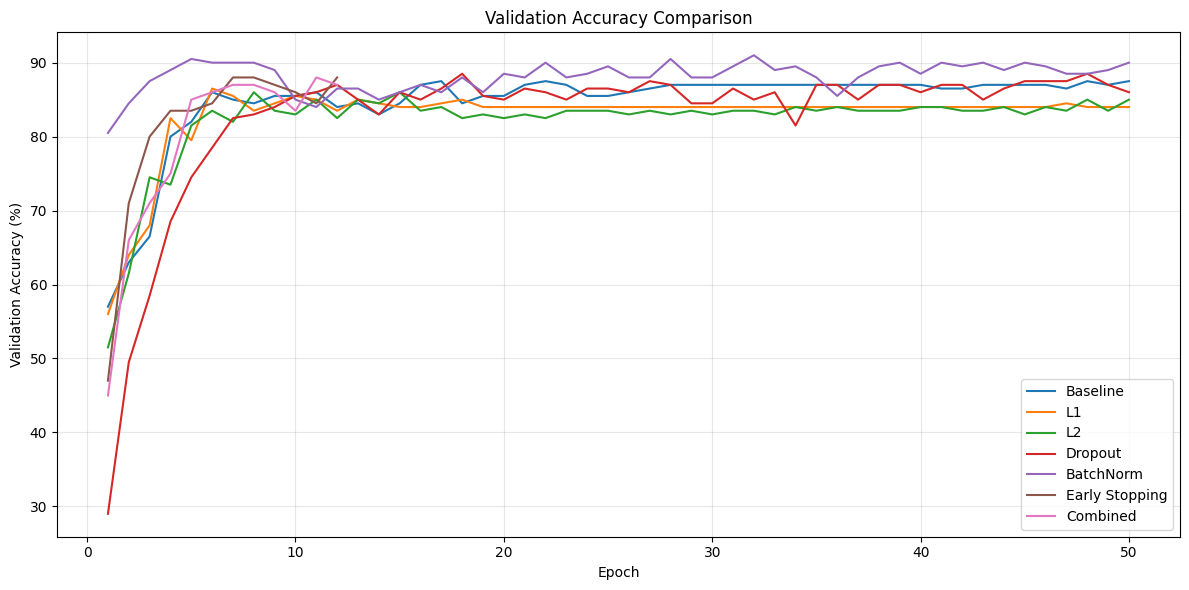

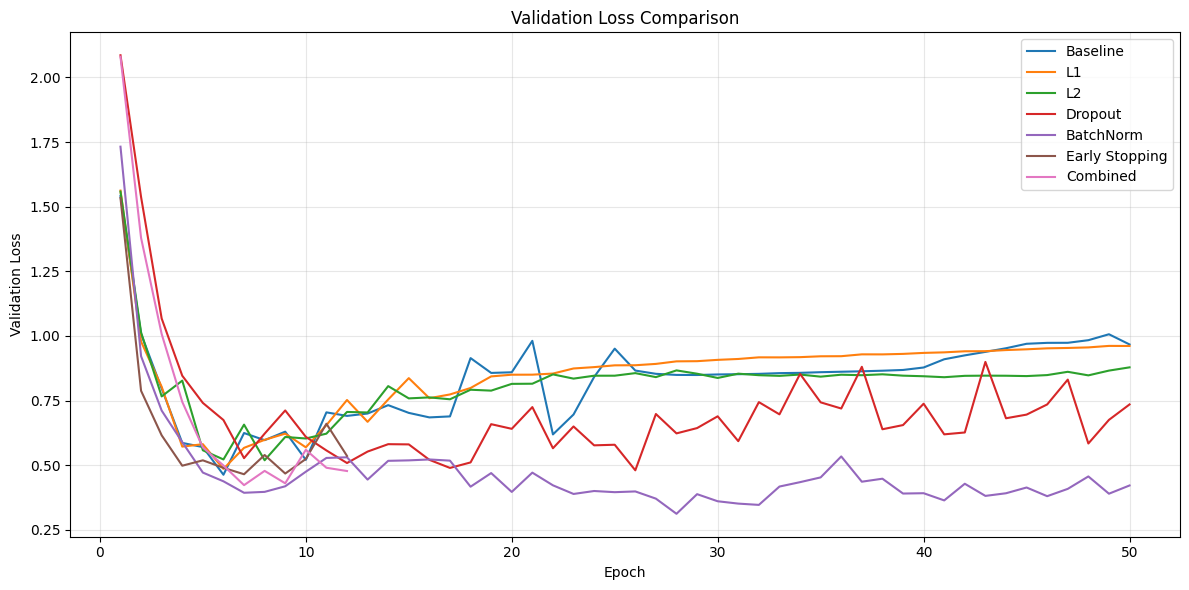

In [28]:
# ============================================================
# CELL 18: Validation Curve Comparison
# ============================================================

histories = {
    "Baseline": baseline_history,
    "L1": l1_history,
    "L2": l2_history,
    "Dropout": dropout_history,
    "BatchNorm": batchnorm_history,
    "Early Stopping": early_stop_history,
    "Combined": combined_history
}

plt.figure(figsize=(12, 6))

for name, history in histories.items():
    plt.plot(
        range(1, len(history["val_acc"]) + 1),
        np.array(history["val_acc"]) * 100,
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.title("Validation Accuracy Comparison")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))

for name, history in histories.items():
    plt.plot(
        range(1, len(history["val_loss"]) + 1),
        history["val_loss"],
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss Comparison")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 8. Test Set Evaluation

All models are evaluated on the held-out MNIST test set. The test set is not used during model training.

In [29]:
# ============================================================
# CELL 19: Evaluate All Models
# ============================================================

models = {
    "Baseline": baseline_model,
    "L1": l1_model,
    "L2": l2_model,
    "Dropout": dropout_model,
    "BatchNorm": batchnorm_model,
    "Early Stopping": early_stop_model,
    "Combined": combined_model
}

results = []

for name, model in models.items():
    test_acc, y_true, y_pred = evaluate_model(
        model,
        test_loader
    )

    history = histories[name]

    results.append({
        "Model": name,
        "Test Accuracy (%)": test_acc * 100,
        "Best Validation Accuracy (%)": max(history["val_acc"]) * 100,
        "Best Validation Loss": min(history["val_loss"]),
        "Epochs Trained": len(history["train_loss"])
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    "Test Accuracy (%)",
    ascending=False
).reset_index(drop=True)

results_df

,Model,Test Accuracy (%),Best Validation Accuracy (%),Best Validation Loss,Epochs Trained
0,BatchNorm,89.84,91.0,0.311899,50
1,Combined,89.64,88.0,0.422707,12
2,Dropout,89.26,88.5,0.480133,50
3,Baseline,88.95,87.5,0.462985,50
4,L1,88.54,86.5,0.485653,50
5,L2,87.91,86.0,0.518985,50
6,Early Stopping,86.50,88.0,0.464907,12


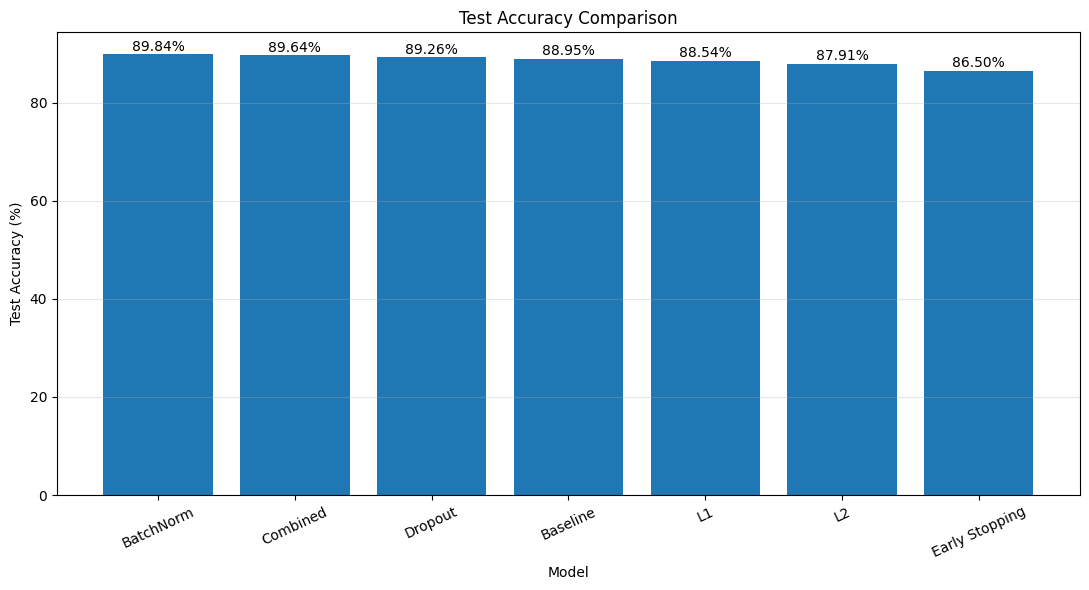

In [30]:
# ============================================================
# CELL 20: Accuracy Comparison Graph
# ============================================================

plt.figure(figsize=(11, 6))

bars = plt.bar(
    results_df["Model"],
    results_df["Test Accuracy (%)"]
)

plt.ylabel("Test Accuracy (%)")
plt.xlabel("Model")
plt.title("Test Accuracy Comparison")
plt.xticks(rotation=25)
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(
    bars,
    results_df["Test Accuracy (%)"]
):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.1,
        f"{value:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

# 9. Confusion Matrix Analysis

The model with the highest test accuracy is selected for detailed classification analysis.

The confusion matrix allows us to identify:

- correctly classified digits,
- frequently confused digit pairs,
- class-specific weaknesses.

In [31]:
# ============================================================
# CELL 21: Select Best Model
# ============================================================

best_model_name = results_df.iloc[0]["Model"]
best_model = models[best_model_name]

best_accuracy, y_true, y_pred = evaluate_model(
    best_model,
    test_loader
)

print("Best model:", best_model_name)
print(f"Test accuracy: {best_accuracy * 100:.2f}%")

Best model: BatchNorm
Test accuracy: 89.84%


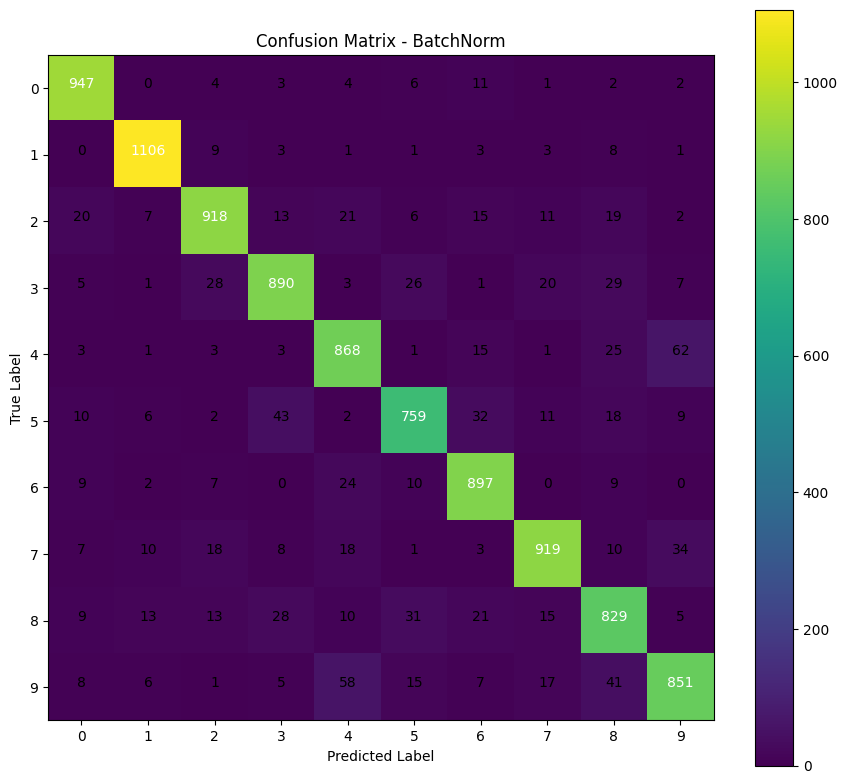

In [32]:
# ============================================================
# CELL 22: Confusion Matrix
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(9, 8))

plt.imshow(cm, interpolation="nearest")
plt.title(f"Confusion Matrix - {best_model_name}")
plt.colorbar()

tick_marks = np.arange(10)

plt.xticks(tick_marks, range(10))
plt.yticks(tick_marks, range(10))

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

threshold = cm.max() / 2

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j,
            i,
            str(cm[i, j]),
            horizontalalignment="center",
            color="white" if cm[i, j] > threshold else "black"
        )

plt.tight_layout()
plt.show()

In [33]:
# ============================================================
# CELL 23: Classification Report
# ============================================================

report = classification_report(
    y_true,
    y_pred,
    target_names=[str(i) for i in range(10)],
    output_dict=True
)

report_df = pd.DataFrame(report).transpose()

report_df

,precision,recall,f1-score,support
0,0.930255,0.966327,0.947948,980.0000
1,0.960069,0.974449,0.967206,1135.0000
2,0.915254,0.889535,0.902211,1032.0000
3,0.893574,0.881188,0.887338,1010.0000
4,0.860258,0.883910,0.871924,982.0000
5,0.886682,0.850897,0.868421,892.0000
6,0.892537,0.936326,0.913907,958.0000
7,0.920842,0.893969,0.907206,1028.0000
8,0.837374,0.851129,0.844196,974.0000
9,0.874615,0.843409,0.858729,1009.0000


## 10. Most Confused Digit Pairs

The following analysis removes the diagonal of the confusion matrix, because diagonal entries represent correct predictions. The remaining largest values show the most common misclassification pairs.

In [34]:
# ============================================================
# CELL 24: Most Confused Classes
# ============================================================

cm_offdiag = cm.copy()
np.fill_diagonal(cm_offdiag, 0)

pairs = []

for true_label in range(10):
    for predicted_label in range(10):
        if true_label != predicted_label:
            pairs.append((
                cm_offdiag[true_label, predicted_label],
                true_label,
                predicted_label
            ))

pairs.sort(reverse=True)

print("Top 10 confusion pairs:")
print()

for count, true_label, predicted_label in pairs[:10]:
    print(
        f"True {true_label} -> Predicted {predicted_label}: "
        f"{count} samples"
    )

Top 10 confusion pairs:

True 4 -> Predicted 9: 62 samples
True 9 -> Predicted 4: 58 samples
True 5 -> Predicted 3: 43 samples
True 9 -> Predicted 8: 41 samples
True 7 -> Predicted 9: 34 samples
True 5 -> Predicted 6: 32 samples
True 8 -> Predicted 5: 31 samples
True 3 -> Predicted 8: 29 samples
True 8 -> Predicted 3: 28 samples
True 3 -> Predicted 2: 28 samples


# 11. Visualize Misclassified Images

The following cells display examples that the best model classified incorrectly. This helps connect the numerical confusion matrix to actual handwritten examples.

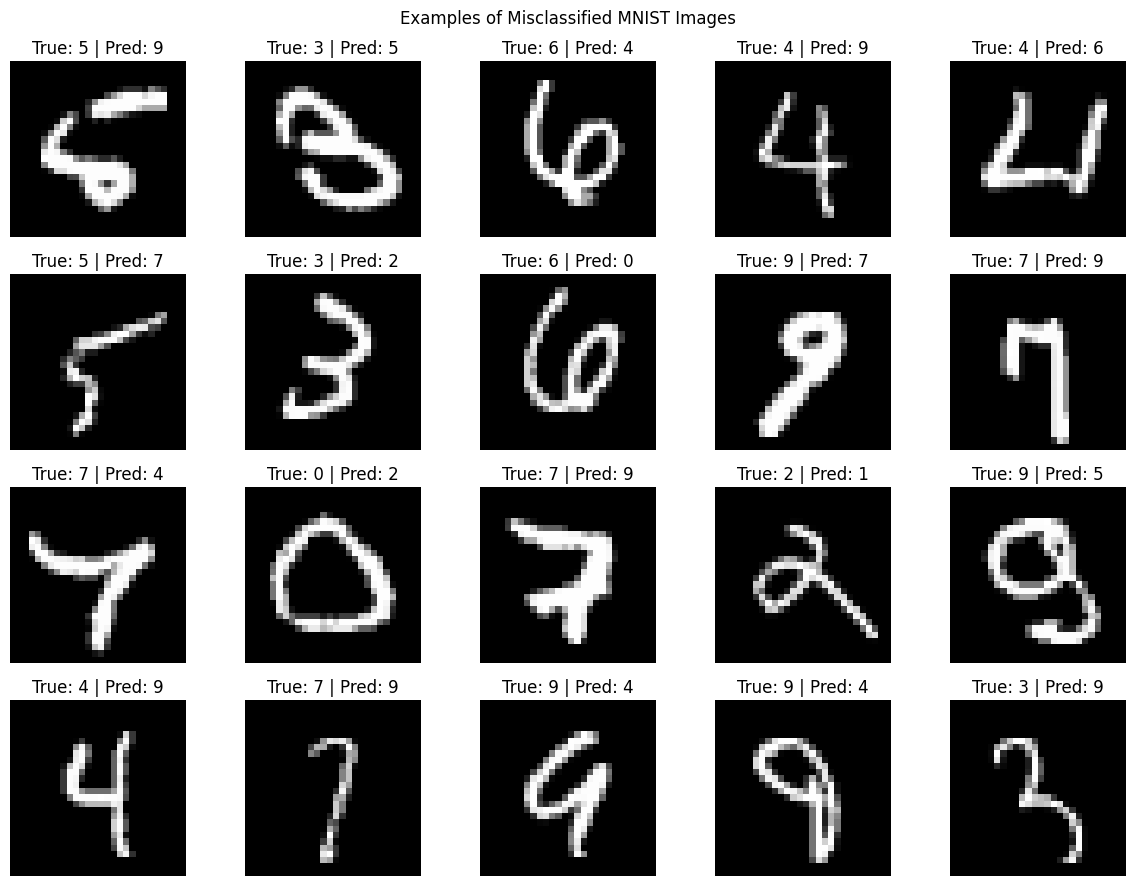

In [35]:
# ============================================================
# CELL 25: Misclassified Images
# ============================================================

best_model.eval()

wrong_images = []
wrong_labels = []
wrong_predictions = []

with torch.no_grad():
    for images, labels in test_loader:
        images_device = images.to(device)

        outputs = best_model(images_device)
        predictions = outputs.argmax(dim=1).cpu()

        wrong = predictions != labels

        for img, true_label, pred_label in zip(
            images[wrong],
            labels[wrong],
            predictions[wrong]
        ):
            wrong_images.append(img)
            wrong_labels.append(true_label)
            wrong_predictions.append(pred_label)

            if len(wrong_images) >= 20:
                break

        if len(wrong_images) >= 20:
            break

plt.figure(figsize=(12, 9))

for i in range(len(wrong_images)):
    plt.subplot(4, 5, i + 1)

    img = wrong_images[i].squeeze().numpy()
    img = img * 0.3081 + 0.1307

    plt.imshow(img, cmap="gray")
    plt.title(
        f"True: {wrong_labels[i].item()} | "
        f"Pred: {wrong_predictions[i].item()}"
    )
    plt.axis("off")

plt.suptitle("Examples of Misclassified MNIST Images")
plt.tight_layout()
plt.show()

# 12. Parameter Sparsity Check for L1

L1 regularization can encourage parameters toward zero. The following is a simple diagnostic comparison between the baseline and L1 models.

This is an observational metric rather than a claim that every L1 model will become sparse.

In [36]:
# ============================================================
# CELL 26: Compare Near-Zero Parameters
# ============================================================

def near_zero_ratio(model, threshold=1e-3):
    total = 0
    near_zero = 0

    for param in model.parameters():
        values = param.detach().cpu().numpy().ravel()

        total += values.size
        near_zero += np.sum(np.abs(values) < threshold)

    return near_zero / total

baseline_zero_ratio = near_zero_ratio(baseline_model)
l1_zero_ratio = near_zero_ratio(l1_model)

sparsity_df = pd.DataFrame({
    "Model": ["Baseline", "L1"],
    "Near-zero parameter ratio (%)": [
        baseline_zero_ratio * 100,
        l1_zero_ratio * 100
    ]
})

sparsity_df

,Model,Near-zero parameter ratio (%)
0,Baseline,2.678240
1,L1,25.005627


In [37]:
# ============================================================
# CELL 27: Final Summary Table
# ============================================================

final_summary = results_df.copy()

final_summary["Generalization Gap (%)"] = (
    final_summary["Best Validation Accuracy (%)"]
    - final_summary["Test Accuracy (%)"]
)

final_summary

,Model,Test Accuracy (%),Best Validation Accuracy (%),Best Validation Loss,Epochs Trained,Generalization Gap (%)
0,BatchNorm,89.84,91.0,0.311899,50,1.16
1,Combined,89.64,88.0,0.422707,12,-1.64
2,Dropout,89.26,88.5,0.480133,50,-0.76
3,Baseline,88.95,87.5,0.462985,50,-1.45
4,L1,88.54,86.5,0.485653,50,-2.04
5,L2,87.91,86.0,0.518985,50,-1.91
6,Early Stopping,86.50,88.0,0.464907,12,1.50


# 13. Discussion

Use the following questions when writing the laboratory discussion:

1. Did the baseline model show a noticeable difference between training and validation performance?
2. Which regularization technique produced the highest test accuracy in this run?
3. Did Dropout reduce the training accuracy compared with the baseline?
4. How did L1 affect the number of near-zero parameters?
5. How did L2 affect validation loss and test accuracy?
6. Did Batch Normalization make training more stable?
7. At which epoch did Early Stopping terminate training?
8. Which digit pairs were most frequently confused?
9. Does the confusion matrix show any class that is particularly difficult to classify?
10. Did the combined model outperform every individual technique? Why might that or might that not happen?

### Important interpretation

There is no guarantee that one regularization method will always produce the best result. Performance depends on:

- training-set size,
- model capacity,
- regularization strength,
- learning rate,
- batch size,
- random initialization,
- number of training epochs,
- and the characteristics of the dataset.

# 14. Conclusion

In this experiment, a high-capacity neural network was trained on a deliberately small MNIST training subset to demonstrate the problem of overfitting and the role of regularization.

L1 and L2 regularization constrain model parameters, Dropout reduces co-adaptation of neurons, Batch Normalization stabilizes intermediate representations, and Early Stopping prevents continued optimization after validation performance stops improving.

The confusion matrix and classification report provide a detailed view of the final classifier's errors beyond overall accuracy.

**Final conclusion should be completed using the actual numerical results generated in the notebook.** Avoid reporting fixed accuracy values from an example run because results can change across executions.

# 15. Viva / Lab Questions

### Short Questions

**Q1. What is overfitting?**  
Overfitting occurs when a model learns the training data too specifically and fails to generalize well to unseen data.

**Q2. What is the purpose of regularization?**  
Regularization reduces overfitting and encourages better generalization.

**Q3. What is the difference between L1 and L2 regularization?**  
L1 penalizes the absolute magnitude of parameters, while L2 penalizes their squared magnitude.

**Q4. What does Dropout do?**  
Dropout randomly deactivates neurons during training.

**Q5. Why is Early Stopping useful?**  
It prevents unnecessary training after validation performance stops improving.

**Q6. What is Batch Normalization?**  
It normalizes intermediate activations and can make optimization more stable.

**Q7. What does the diagonal of a confusion matrix represent?**  
Correct predictions for each class.

**Q8. What do off-diagonal values represent?**  
Misclassifications between different classes.

# 16. Optional: Save the Best Model

The trained best model can be saved for later use.

In [38]:
# ============================================================
# CELL 28: Save Best Model
# ============================================================

MODEL_PATH = "best_regularized_mnist_model.pth"

torch.save(
    {
        "model_name": best_model_name,
        "model_state_dict": best_model.state_dict(),
        "test_accuracy": best_accuracy
    },
    MODEL_PATH
)

print("Saved:", MODEL_PATH)

Saved: best_regularized_mnist_model.pth
